# Bài 19 - Experiment 2: Number of attention heads

So sánh n_heads = 1, 2, 4, 8 trong cùng một Transformer classifier. Giữ d_model = 128, split dữ liệu, vocabulary, batch size, optimizer, learning rate và số epoch cố định. Với mỗi cấu hình, notebook đo Parameters, Training time, Accuracy và F1 trên IMDb.

Nếu lớp yêu cầu đúng dataset của LAB 05, thay phần nạp dữ liệu bằng split/vocabulary của LAB 05 nhưng giữ nguyên các cấu hình còn lại. Ghi dự đoán trước khi chạy; không dùng số liệu subset làm kết quả cuối.

In [ ]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets import imdb
from tensorflow.keras.utils import pad_sequences

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

D_MODEL = 128
D_FF = 256
HEADS_TO_TEST = [1, 2, 4, 8]
MAX_WORDS = 20_000
MAX_LENGTH = 128
BATCH_SIZE = 64
EPOCHS = 3
LEARNING_RATE = 1e-3
DROPOUT = 0.1
TRAIN_LIMIT = None  # Optional small subset for pipeline checks only.

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("d_k per head count:", {h: D_MODEL // h for h in HEADS_TO_TEST})

TensorFlow: 2.21.0
GPU devices: []
d_k per head count: {1: 128, 2: 64, 4: 32, 8: 16}


In [ ]:
(x_trainval_raw, y_trainval), (x_test_raw, y_test) = imdb.load_data(num_words=MAX_WORDS, seed=SEED)
y_trainval = np.asarray(y_trainval, dtype=np.int32)
y_test = np.asarray(y_test, dtype=np.int32)
train_idx, val_idx = train_test_split(
    np.arange(len(y_trainval)), test_size=0.1, random_state=SEED, stratify=y_trainval
)

def pad_reviews(sequences):
    return np.asarray(pad_sequences(
        sequences, maxlen=MAX_LENGTH, padding="post", truncating="post"
    ), dtype=np.int32)

x_train = pad_reviews([x_trainval_raw[i] for i in train_idx])
y_train = y_trainval[train_idx]
x_val = pad_reviews([x_trainval_raw[i] for i in val_idx])
y_val = y_trainval[val_idx]
x_test = pad_reviews(x_test_raw)

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (22500, 128) (22500,)
Validation: (2500, 128) (2500,)
Test: (25000, 128) (25000,)


In [ ]:
# Sinusoidal positional encoding
def positional_encoding(max_length, d_model):
    pos = np.arange(max_length, dtype=np.float32)[:, None]
    dim = np.arange(d_model, dtype=np.float32)[None, :]
    rates = np.power(10000.0, -(2.0 * np.floor(dim / 2.0)) / d_model)
    angles = pos * rates
    pe = np.empty_like(angles)
    pe[:, 0::2] = np.sin(angles[:, 0::2])
    pe[:, 1::2] = np.cos(angles[:, 1::2])
    return tf.constant(pe[None, :, :], dtype=tf.float32)

# Core implementation: split Q/K/V into heads and combine them back to d_model.
class MultiHeadSelfAttention(tf.keras.layers.Layer):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        if d_model % n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.d_model, self.n_heads = d_model, n_heads
        self.d_k = d_model // n_heads
        self.q_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.k_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.v_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.out_proj = tf.keras.layers.Dense(d_model, use_bias=False)
        self.dropout = tf.keras.layers.Dropout(dropout)

    def split_heads(self, x):
        shape = tf.shape(x)
        x = tf.reshape(x, [shape[0], shape[1], self.n_heads, self.d_k])
        return tf.transpose(x, [0, 2, 1, 3])

    def call(self, x, key_mask=None, training=False, return_attention=False):
        q = self.split_heads(self.q_proj(x))
        k = self.split_heads(self.k_proj(x))
        v = self.split_heads(self.v_proj(x))
        scores = tf.matmul(q, k, transpose_b=True) / tf.math.sqrt(tf.cast(self.d_k, tf.float32))
        if key_mask is not None:
            mask = tf.cast(key_mask[:, None, None, :], tf.bool)
            scores = tf.where(mask, scores, tf.cast(-1e9, scores.dtype))
        weights = tf.nn.softmax(scores, axis=-1)
        context = tf.matmul(self.dropout(weights, training=training), v)
        context = tf.transpose(context, [0, 2, 1, 3])
        shape = tf.shape(context)
        context = tf.reshape(context, [shape[0], shape[1], self.d_model])
        output = self.out_proj(context)
        return (output, weights) if return_attention else output

class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadSelfAttention(d_model, n_heads, dropout)
        self.drop1 = tf.keras.layers.Dropout(dropout)
        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.ffn1 = tf.keras.layers.Dense(d_ff, activation="gelu")
        self.ffn_drop = tf.keras.layers.Dropout(dropout)
        self.ffn2 = tf.keras.layers.Dense(d_model)
        self.drop2 = tf.keras.layers.Dropout(dropout)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)

    def call(self, x, key_mask=None, training=False, return_attention=False):
        result = self.attention(x, key_mask=key_mask, training=training, return_attention=return_attention)
        if return_attention:
            attn_out, weights = result
        else:
            attn_out = result
        x = self.norm1(x + self.drop1(attn_out, training=training))
        ff = self.ffn2(self.ffn_drop(self.ffn1(x), training=training))
        output = self.norm2(x + self.drop2(ff, training=training))
        return (output, weights) if return_attention else output

In [ ]:
class TransformerClassifier(tf.keras.Model):
    def __init__(self, vocab_size, max_length, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.embedding = tf.keras.layers.Embedding(vocab_size, d_model, mask_zero=False)
        self.position = positional_encoding(max_length, d_model)
        self.input_dropout = tf.keras.layers.Dropout(dropout)
        self.block = TransformerBlock(d_model, n_heads, d_ff, dropout)
        self.classifier = tf.keras.layers.Dense(1, activation="sigmoid")

    def call(self, token_ids, training=False, return_attention=False):
        valid_mask = tf.not_equal(token_ids, 0)
        x = self.embedding(token_ids) * tf.math.sqrt(tf.cast(self.d_model, tf.float32))
        x = x + self.position[:, :tf.shape(token_ids)[1], :]
        x = self.input_dropout(x, training=training)
        if return_attention:
            x, weights = self.block(x, key_mask=valid_mask, training=training, return_attention=True)
        else:
            x = self.block(x, key_mask=valid_mask, training=training)
        mask = tf.cast(valid_mask[:, :, None], x.dtype)
        pooled = tf.reduce_sum(x * mask, axis=1) / tf.maximum(tf.reduce_sum(mask, axis=1), 1.0)
        predictions = self.classifier(pooled)
        return (predictions, weights) if return_attention else predictions

def build_model(n_heads):
    model = TransformerClassifier(MAX_WORDS, MAX_LENGTH, D_MODEL, n_heads, D_FF, DROPOUT)
    model(tf.zeros([1, MAX_LENGTH], dtype=tf.int32))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="binary_crossentropy", metrics=["accuracy"]
    )
    return model

In [ ]:
# Shape check before training
for heads in HEADS_TO_TEST:
    d_k = D_MODEL // heads
    dummy = tf.zeros([2, MAX_LENGTH, D_MODEL])
    attention = MultiHeadSelfAttention(D_MODEL, heads, dropout=0.0)
    output, weights = attention(dummy, return_attention=True, training=False)
    print(f"heads={heads}, d_k={d_k}, Q/K/V={(2, heads, MAX_LENGTH, d_k)}, scores={tuple(weights.shape)}, output={tuple(output.shape)}")
    assert tuple(weights.shape) == (2, heads, MAX_LENGTH, MAX_LENGTH)
    assert tuple(output.shape) == (2, MAX_LENGTH, D_MODEL)

heads=1, d_k=128, Q/K/V=(2, 1, 128, 128), scores=(2, 1, 128, 128), output=(2, 128, 128)
heads=2, d_k=64, Q/K/V=(2, 2, 128, 64), scores=(2, 2, 128, 128), output=(2, 128, 128)
heads=4, d_k=32, Q/K/V=(2, 4, 128, 32), scores=(2, 4, 128, 128), output=(2, 128, 128)
heads=8, d_k=16, Q/K/V=(2, 8, 128, 16), scores=(2, 8, 128, 128), output=(2, 128, 128)



Training n_heads=1, d_k=128
Epoch 1/3
352/352 - 101s - 286ms/step - accuracy: 0.8049 - loss: 0.4161 - val_accuracy: 0.8516 - val_loss: 0.3564
Epoch 2/3
352/352 - 140s - 398ms/step - accuracy: 0.9175 - loss: 0.2112 - val_accuracy: 0.8384 - val_loss: 0.4820
Epoch 3/3
352/352 - 96s - 274ms/step - accuracy: 0.9597 - loss: 0.1095 - val_accuracy: 0.8276 - val_loss: 0.6345

Training n_heads=2, d_k=64
Epoch 1/3
352/352 - 101s - 287ms/step - accuracy: 0.8045 - loss: 0.4167 - val_accuracy: 0.8528 - val_loss: 0.3531
Epoch 2/3
352/352 - 141s - 402ms/step - accuracy: 0.9166 - loss: 0.2131 - val_accuracy: 0.8412 - val_loss: 0.4721
Epoch 3/3
352/352 - 101s - 287ms/step - accuracy: 0.9597 - loss: 0.1124 - val_accuracy: 0.8292 - val_loss: 0.6059

Training n_heads=4, d_k=32
Epoch 1/3
352/352 - 116s - 329ms/step - accuracy: 0.8043 - loss: 0.4160 - val_accuracy: 0.8524 - val_loss: 0.3488
Epoch 2/3
352/352 - 114s - 323ms/step - accuracy: 0.9151 - loss: 0.2147 - val_accuracy: 0.8480 - val_loss: 0.4565
Epoc

,Heads,d_k,Parameters,Training time (s),Accuracy,F1
0,1,128,2692097,382.96,0.7878,0.7763
1,2,64,2692097,343.61,0.7868,0.7715
2,4,32,2692097,371.25,0.7945,0.7873
3,8,16,2692097,426.98,0.7850,0.7614


Parameter counts identical: True


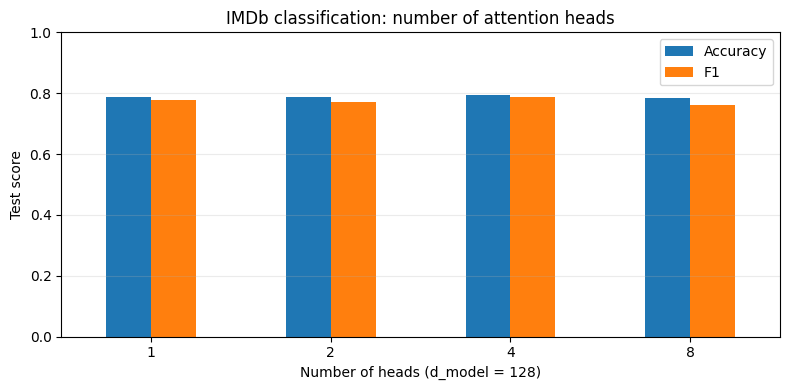

In [ ]:
# Training time is measured for fit only; test metrics are computed afterward.
results = []
for n_heads in HEADS_TO_TEST:
    print(f"\nTraining n_heads={n_heads}, d_k={D_MODEL // n_heads}")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(n_heads)
    started = time.perf_counter()
    model.fit(
        x_train, y_train, validation_data=(x_val, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=2
    )
    training_seconds = time.perf_counter() - started
    probabilities = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(np.int32)
    results.append({
        "Heads": n_heads,
        "d_k": D_MODEL // n_heads,
        "Parameters": model.count_params(),
        "Training time (s)": round(training_seconds, 2),
        "Accuracy": accuracy_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
    })

results_df = pd.DataFrame(results).sort_values("Heads").reset_index(drop=True)
display(results_df.style.format({"Training time (s)": "{:.2f}", "Accuracy": "{:.4f}", "F1": "{:.4f}"}))
print("Parameter counts identical:", results_df["Parameters"].nunique() == 1)

ax = results_df.set_index("Heads")[["Accuracy", "F1"]].plot(
    kind="bar", figsize=(8, 4), ylim=(0, 1), rot=0,
    title="IMDb classification: number of attention heads"
)
ax.set_ylabel("Test score")
ax.set_xlabel("Number of heads (d_model = 128)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Câu hỏi và kết luận

- Tăng số heads có làm tăng representation dimension không? **Không.** d_model vẫn bằng 128; sau khi nối các heads, chiều representation vẫn là 128.
- Khi d_model cố định, d_k = d_model / n_heads. Với 1, 2, 4, 8 heads, d_k lần lượt là 128, 64, 32, 16.
- Số tham số trong implementation này dự kiến không đổi theo số heads vì các phép chiếu Q/K/V/output vẫn có kích thước 128 → 128.

